### Para conocer qué versión de Python y la ruta del ejecutable 

In [10]:
import sys
print("Ruta exacta del ejecutable:", sys.executable)
print("Versión en uso:", sys.version)

Ruta exacta del ejecutable: c:\Projects\Telco-Churn\.venv\Scripts\python.exe
Versión en uso: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]


### Telecom. Descarga del fichero con el contenido de los datos de los clientes para estudiar la predicción de la fuga de clientes (Churn)

In [11]:
# Descarga del fichero con información de clientes
!curl -L -o data/data_churn.csv https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
100 947.7k 100 947.7k   0      0  2.89M      0                              0
100 947.7k 100 947.7k   0      0  2.89M      0                              0
100 947.7k 100 947.7k   0      0  2.88M      0                              0


### Exploración inicial de datos
 - Filas: 7.043
 - Columnas: 21 
 Todos los campos rellenos, la mayoria son strings

 Variable Objetivo: **Churn**. La muestra está **desbalanceada**. No: 0.73463, Yes: 0.26537. 
 Habrá que contralar que esta desproporción sea la misma en el conjunto de entrenamiento y en el de prueba (en la función train_test_split, ver parámetro stratify=y  que mantiene la misma proporción de Churn en train y test)




In [1]:
# %pip install pandas scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# %pip install xgboost seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import pandas as pd

# Generación de Dataframe con la información del fichero descargado
df = pd.read_csv("data/data_churn.csv")

# Mostrar las primeras filas del DataFrame
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [13]:
# Información de los campos del dataframe
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [14]:
# Proporción del campo objetivo 
df['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [15]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [16]:
# Al intentar parsear de str a número, detecta espacio en blanco " " y lanza error:  Unable to parse string " " at position 488
# Vemos qué filas está ocurriendo esto antes de proceder a cambiar " " por valor nulo
#pd.to_numeric(df['TotalCharges']) --> ERROR Unable to parse string " " at position 488

# Cuenta solo las filas donde 'TotalCharges' contiene únicamente espacios en blanco. En total 11 filas
#cantidad = (df['TotalCharges'].str.strip() == '').sum()
#print(f"Hay {cantidad} filas con espacios en blanco.")

# Pasamos a numérico el campo y controlamos los nulos como NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [17]:
# Se observa el cambio del tipo de dato
#df.info()

# Se visualizan los 11 registros con el valor NaN
df[df['TotalCharges'].isna()]


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [18]:
# Viendo los datos NaN en TotalCharges, están relacionados con la antigüedad del cliente, tenure = 0, por lo que es normal que valga nulo porque aun no se ha generado factura
# Se procede a actualizar los NaN con 0
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)


In [19]:
# copia del df para poder modificar/eliminar variables 
df2 = df

df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [20]:

# Eliminar del df el customerID ya que no aporta
df2 = df2.drop(columns=['customerID'], errors='ignore')

# Mapeo directo de 'Yes'/'No' a 1/0
df2['Churn'] = df2['Churn'].map({'Yes': 1, 'No': 0})
df2['Partner'] = df2['Partner'].map({'Yes': 1, 'No': 0})
df2['Dependents'] = df2['Dependents'].map({'Yes': 1, 'No': 0})
df2['PhoneService'] = df2['PhoneService'].map({'Yes': 1, 'No': 0})
df2['PaperlessBilling'] = df2['PaperlessBilling'].map({'Yes': 1, 'No': 0})


In [21]:
# consultar valores posibles dentro de cada campo 
#df2['MultipleLines'].value_counts(dropna=False)
#df2['gender'].value_counts(dropna=False)

df2.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,Male,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,Male,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,Male,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


In [22]:
# Para ver si las variables tienen relación con el Churn
resumen = df2.groupby('Contract')['Churn'].agg(
    Total_Clientes='count',
    Clientes_Churn='sum',
    Porcentaje_Churn=lambda x: round(x.mean() * 100, 2)
).reset_index()

resumen

,Contract,Total_Clientes,Clientes_Churn,Porcentaje_Churn
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


In [23]:
# Continuación de la codificación de variables CATEGÓRICAS
# Previamente a codificar como one-hot las variables categóricas de un sólo golpe, se actualizan las variables ordinales, en este caso Contract

# Definir el diccionario con la jerarquía
mapeo_contrato = {
    'Month-to-month': 1,
    'One year': 2,
    'Two year': 3
}

# Aplicar la transformación directamente a la columna
df2['Contract'] = df2['Contract'].map(mapeo_contrato)

# Verificar que el tipo de dato ahora es int64 y revisar la distribución
print(f"Nuevo tipo de dato: {df2['Contract'].dtype}")
df2['Contract'].value_counts()



Nuevo tipo de dato: int64


Contract
1    3875
3    1695
2    1473
Name: count, dtype: int64

In [24]:
# Comprobar que no hayan quedado nulos tras el mapeo
assert df2['Contract'].isna().sum() == 0, "Hay valores en Contract que no se pudieron mapear"

In [25]:
# Actualización de la codificación a ONE-HOT de las restantes variables categóricas

# 1. Identificar automáticamente las columnas categóricas (de tipo 'object' o 'category')
columnas_nominales = df2.select_dtypes(include=['object', 'category']).columns.tolist()

print("Columnas nominales detectadas para One-Hot Encoding:")
print(columnas_nominales)

# 2. Aplicar One-Hot Encoding automáticamente
# - drop_first=True: elimina la primera categoría para evitar la trampa de variables dummy (multicolinealidad)
df_encoded = pd.get_dummies(
    df2, 
    columns=columnas_nominales, 
    drop_first=True, 
    dtype=int
)

# 3. Ver las primeras filas del nuevo DataFrame
df_encoded.head()

Columnas nominales detectadas para One-Hot Encoding:
['gender', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaymentMethod']


C:\Users\Usuario\AppData\Local\Temp\ipykernel_138536\1104704536.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_nominales = df2.select_dtypes(include=['object', 'category']).columns.tolist()


,SeniorCitizen,Partner,Dependents,tenure,PhoneService,Contract,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,0,1,0,1,1,29.85,29.85,0,...,0,0,0,0,0,0,0,0,1,0
1,0,0,0,34,1,2,0,56.95,1889.50,0,...,1,0,0,0,0,0,0,0,0,1
2,0,0,0,2,1,1,1,53.85,108.15,1,...,0,0,0,0,0,0,0,0,0,1
3,0,0,0,45,0,2,0,42.30,1840.75,0,...,1,0,1,0,0,0,0,0,0,0
4,0,0,0,2,1,1,1,70.70,151.65,1,...,0,0,0,0,0,0,0,0,1,0


In [26]:
df_encoded.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 30 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   SeniorCitizen                          7043 non-null   int64  
 1   Partner                                7043 non-null   int64  
 2   Dependents                             7043 non-null   int64  
 3   tenure                                 7043 non-null   int64  
 4   PhoneService                           7043 non-null   int64  
 5   Contract                               7043 non-null   int64  
 6   PaperlessBilling                       7043 non-null   int64  
 7   MonthlyCharges                         7043 non-null   float64
 8   TotalCharges                           7043 non-null   float64
 9   Churn                                  7043 non-null   int64  
 10  gender_Male                            7043 non-null   int64  
 11  MultipleLines_N

### Modelado 
Una vez que tenemos codificados los datos, es hora de lanzar el primer modelo base, Logistic Reg

In [27]:
# Separar el dataset en la matriz de características X y el vector objetivo y (Churn).
y = df_encoded['Churn']

X = df_encoded.drop(columns=['Churn'])

print(f"Dimensiones de X (características): {X.shape}")
print(f"Dimensiones de y (target): {y.shape}")

Dimensiones de X (características): (7043, 29)
Dimensiones de y (target): (7043,)


In [28]:
# Separar los datos de entreno y validación 

from sklearn.model_selection import train_test_split

# Dividir los datos en 80-20% para entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y  # Mantiene la misma proporción de Churn en train y test
)

# Verificar el volumen de datos en cada conjunto
print(f"Registros en X_train: {X_train.shape[0]}")
print(f"Registros en X_test:  {X_test.shape[0]}")

Registros en X_train: 5634
Registros en X_test:  1409


### Prueba del modelo de Regresión logística
La ejecución eleva un warning que indica que las iteraciones no han sido suficientes para llegar a converger y encontrar los coeficientes óptimos definitivos:
ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Los motivos pueden ser: 
1. Diferencia de escalas en las variables (Causa principal). Ver columnas TotalCharges (0 a 8000), MonthlyCharges (0 a 118), y tenure (0 a 72) y columnas dummy de One-Hot Encoding.
En pasos posteriores haremos un escalado de estas variables.
2. Multicolinealidad o gran volumen de variables.


In [29]:
# Entreno un modelo sencillo de Regresión Logística y realizo una predicción

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

model_lr = LogisticRegression(max_iter=1000, random_state=42)
model_lr.fit(X_train, y_train)

y_pred_lr = model_lr.predict(X_test)
y_pred_proba_lr = model_lr.predict_proba(X_test)[:, 1]

# 4. Mostrar métricas de evaluación principales
print("--- Informe de Clasificación ---")
print(classification_report(y_test, y_pred_lr))

print("--- Matriz de Confusión ---")
print(confusion_matrix(y_test, y_pred_lr))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_lr):.4f}")



--- Informe de Clasificación ---
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.65      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.80      0.80      0.80      1409

--- Matriz de Confusión ---
[[924 111]
 [166 208]]
ROC-AUC Score: 0.8426


c:\Projects\Telco-Churn\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [30]:
# Función que muestra la Matriz de Confusión y la curva ROC-AUC.
# Creamos la función porque la vamos a utilizar para varios modelos 

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

def evaluar_modelo_individual(model, X_test_data, y_test_data, nombre_modelo="Modelo"):
    """
    Genera la Matriz de Confusión y la Curva ROC-AUC para un modelo específico.
    
    Parámetros:
    -----------
    model : estimator de scikit-learn o xgboost
        El modelo ya entrenado.
    X_test_data : pd.DataFrame o np.ndarray
        Conjunto de características de prueba (escalado o sin escalar según el modelo).
    y_test_data : pd.Series o np.ndarray
        Etiquetas reales de prueba.
    nombre_modelo : str
        Nombre del modelo para mostrar en los títulos y leyenda.
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # 1. Matriz de Confusión
    ConfusionMatrixDisplay.from_estimator(
        model, 
        X_test_data, 
        y_test_data, 
        cmap='Blues', 
        display_labels=['No Churn (0)', 'Churn (1)'],
        ax=axes[0]
    )
    axes[0].set_title(f'Matriz de Confusión - {nombre_modelo}', fontsize=12, fontweight='bold')

    # 2. Curva ROC-AUC
    RocCurveDisplay.from_estimator(
        model, 
        X_test_data, 
        y_test_data, 
        ax=axes[1],
        name=nombre_modelo
    )
    # Línea diagonal de referencia (clasificador aleatorio)
    axes[1].plot([0, 1], [0, 1], color='navy', linestyle='--', label='Aleatorio (AUC = 0.50)')
    axes[1].set_title(f'Curva ROC-AUC - {nombre_modelo}', fontsize=12, fontweight='bold')
    axes[1].legend(loc='lower right')
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

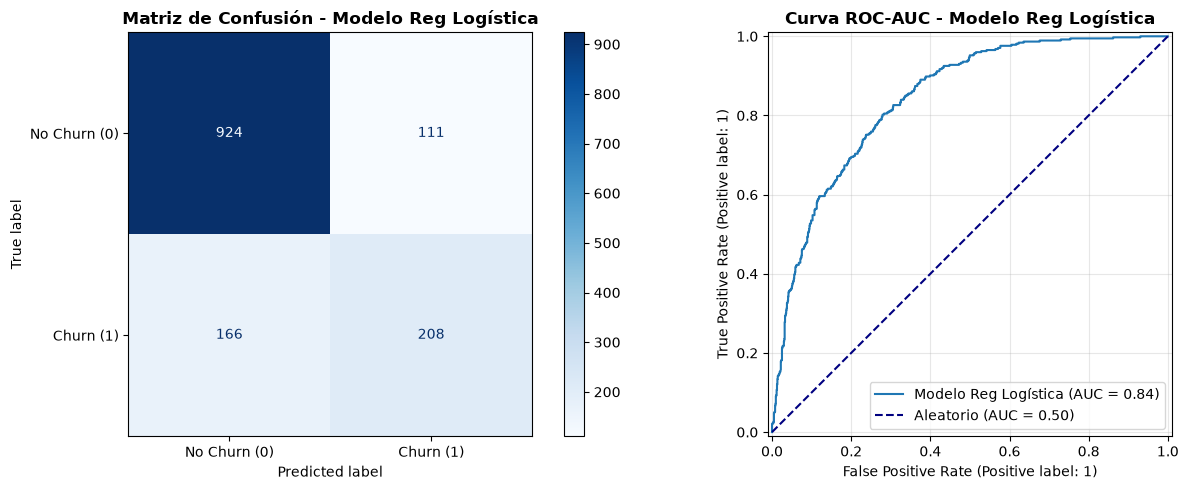

In [31]:
# Muestra la Matriz de Confusión y la curva ROC-AUC.

evaluar_modelo_individual(model_lr, X_test, y_test, nombre_modelo="Modelo Reg Logística")

### Resultados Logistic Reg
Revisando la matriz de confusión y las métricas:
- Tenemos un Accuracy del 80%. Es un buen valor, pero ojo que los datos están desbalanceados por lo que no nos podemos fiar. 
- Fijándonos en la vable churn(1), tenemos APROX una precisión de 65% y un recall de 56%. 
- En problemas como el Churn, recall es la métrica a mejorar, ya que queremos minimizar los FN, Falsos Negativos, es decir, los clientes que son Churn pero que el modelo ha predicho como NoChurn.


### Estandarización de datos sobre el modelo
Repetimos la ejecución del modelo pero empleando datos estandarizados, ya que el modelo de Logistic Reg está influenciado por la escala de las variables numéricas. 
Las métricas del informe de clasificación apenas cambian, solo cambia la escala, no la relación. El escalado sirve para converger antes, y permite comparar la importancia real de las variables mirando directamente sus coeficientes.

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# OJO: fit_transform SOLO en train, transform en test para evitar Data Leakage
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']  
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

# Se entrena nuevo modelo pero ahora con variables escaladas
model_lrstd = LogisticRegression(max_iter=1000, random_state=42)
model_lrstd.fit(X_train_scaled, y_train)

y_pred_std = model_lrstd.predict(X_test_scaled)
y_pred_proba_std = model_lrstd.predict_proba(X_test_scaled)[:, 1]

# 4. Mostrar métricas de evaluación principales
print("--- Informe de Clasificación (con datos escalados) ---")
print(classification_report(y_test, y_pred_std))

print("--- Matriz de Confusión ---")
print(confusion_matrix(y_test, y_pred_std))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_std):.4f}")




--- Informe de Clasificación (con datos escalados) ---
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

--- Matriz de Confusión ---
[[925 110]
 [164 210]]
ROC-AUC Score: 0.8421


### Influencia de las características en el cálculo del Churn.

- Para Logistic reg tenemos: 
    - tenure
    - InternetService_Fiber optic
    - Contract
    - TotalCharges                
    - MonthlyCharges

- Para RF, XGBoost las veremos más adelante, pero ya adelanto que son practicamente las mismas.

- Para un mejor entendimiento, utilizaremos libreria Shap que permite mostrar en un gráfico la influencia de las características por medio de diferentes ejes.


In [33]:
# Para conocer qué variables aumentan o reducen la probabilidad de Churn

import numpy as np 

# 1. Crear un DataFrame con las características y sus coeficientes
coef_df = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'Coeficiente': model_lrstd.coef_[0]
})

# 2. Calcular los Odds Ratios (Exponencial del coeficiente)
# Un Odds Ratio > 1 aumenta el riesgo de Churn; < 1 lo reduce.
coef_df['Odds_Ratio'] = np.exp(coef_df['Coeficiente'])

# 3. Ordenar de mayor a menor impacto
coef_df = coef_df.sort_values(by='Coeficiente', ascending=False).reset_index(drop=True)

# Mostrar las 10 características que más AUMENTAN el Churn
print(" Top factores que AUMENTAN el riesgo de Churn:")
display(coef_df.head(10))

# Mostrar las 10 características que más REDUCEN el Churn
print("\n Top factores que RETIENEN al cliente (REDUCEN Churn):")
display(coef_df.tail(10))

 Top factores que AUMENTAN el riesgo de Churn:


,Feature,Coeficiente,Odds_Ratio
0,InternetService_Fiber optic,1.185451,3.272161
1,TotalCharges,0.525179,1.690762
2,PaymentMethod_Electronic check,0.377156,1.458131
3,StreamingMovies_Yes,0.375514,1.455740
4,StreamingTV_Yes,0.374973,1.454952
5,PaperlessBilling,0.370510,1.448473
6,MultipleLines_Yes,0.361559,1.435566
7,SeniorCitizen,0.140718,1.151100
8,PaymentMethod_Mailed check,0.065791,1.068003
9,DeviceProtection_Yes,0.035023,1.035644



 Top factores que RETIENEN al cliente (REDUCEN Churn):


,Feature,Coeficiente,Odds_Ratio
19,OnlineBackup_No internet service,-0.171784,0.842161
20,InternetService_No,-0.171784,0.842161
21,StreamingTV_No internet service,-0.171784,0.842161
22,Dependents,-0.227049,0.796882
23,TechSupport_Yes,-0.297416,0.742735
24,OnlineSecurity_Yes,-0.347369,0.706544
25,PhoneService,-0.424013,0.654415
26,MonthlyCharges,-0.467866,0.626337
27,Contract,-0.690761,0.501195
28,tenure,-1.247397,0.287252


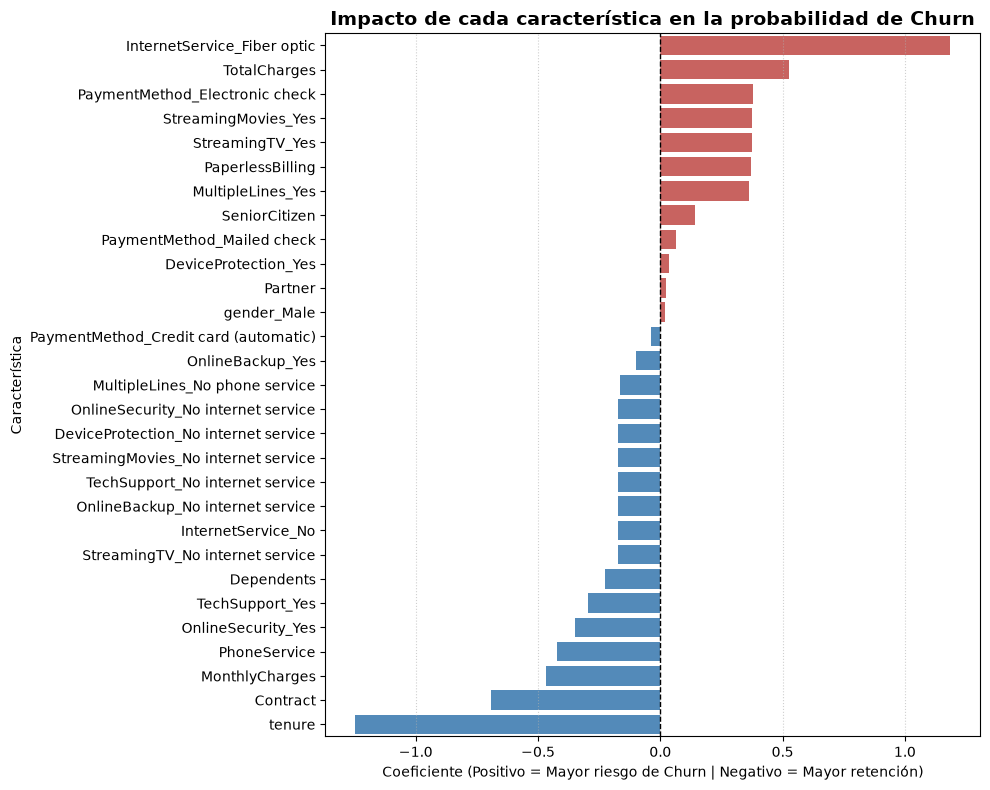

In [34]:
# Visualización de las vabiables con mayor impacto en el churn 

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

# Asignar color rojo si aumenta el Churn (>0) y azul si lo reduce (<0)
colors = ['#d9534f' if c > 0 else '#428bca' for c in coef_df['Coeficiente']]

sns.barplot(data=coef_df, x='Coeficiente', y='Feature', hue='Feature', palette=colors, legend=False)

plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.title('Impacto de cada característica en la probabilidad de Churn', fontsize=14, fontweight='bold')
plt.xlabel('Coeficiente (Positivo = Mayor riesgo de Churn | Negativo = Mayor retención)')
plt.ylabel('Característica')
plt.grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### Continuación de pruebas con otros modelos 

Pruebas con nuevos modelos como Random Forest y XGBoost

- Se entrena un RandomForestClassifier (n_estimators=100, random_state=42). RF tiene posibilidad de generar un listado de características más influyentes en el valor de Churn (lo veremos despues)

- Se entrena un XGBClassifier (n_estimators=100, learning_rate=0.1, random_state=42). Al igual que RF, se puede generar un listado de caracteristicas influyentes.

- Se entrena un XGBClassifier (n_estimators=100, learning_rate=0.1, random_state=42, scale_pos_weight=2.7), pero está vez incluyendo el parámetro scale_pos_weight en XGBoost (calculado como la proporción de valores de la clase 0 entre la proporción de los valores de la clase 1, de los datos de prueba) para indicarle al modelo que le dé más peso a los errores en la clase minoritaria.

- Se genera el informe de clasificación y la matriz de confusión para LR std, RF, y XGB bal. Por ahora el mejor modelo es la regresión logistica con datos estandarizados. 

- Se actualiza el Umbral de Decisión (Threshold Tuning). Al bajar el umbral de considerar clasificar el dato como Churn, tendremos muchos más Falsos Positivos, pero esto hará que bajen los Falsos Negativos que es lo interesante conseguir en proyectos de fuga de clientes. Aumentará la métrica Recall y bajará la Precisión.

- Se genera un listado de de características más influyentes en el valor de Churn, tanto para LR, RF como XGB. Se obtienen campos diferentes porque el modelo aplicado es diferente. 
    - El modelo de RF calcula la importancia en base a la reducción media de la impureza de Gini. Esta técnica tiene un sesgo conocido que sobrevalora las variables continuas con muchos valores únicos (como TotalCharges o MonthlyCharges) frente a variables categóricas o dummies.
    - XGB calcula por la Ganancia, que mide la mejora en la función de pérdida que aporta cada variable al hacer una división (split).
    - En este caso, el consenso es la opción mas sensata, y sería quedarse con el top 5 de ambas salidas.
    - Se instala SHAP (SHapley Additive exPlanations) para interpretar los resultados de las variables más influyentes.



In [35]:
# Entreno un modelo de RandomForest

from sklearn.ensemble import RandomForestClassifier

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

model_rf =RandomForestClassifier (n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)
y_pred_proba_rf = model_rf.predict_proba(X_test)[:, 1]

# 4. Mostrar métricas de evaluación principales
print("--- Informe de Clasificación ---")
print(classification_report(y_test, y_pred_rf))

print("--- Matriz de Confusión ---")
print(confusion_matrix(y_test, y_pred_rf))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_rf):.4f}")

--- Informe de Clasificación ---
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.63      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409

--- Matriz de Confusión ---
[[929 106]
 [190 184]]
ROC-AUC Score: 0.8248


In [36]:
# Entreno un modelo de XGBClassifier (p. ej. n_estimators=100, learning_rate=0.1, random_state=42).

from xgboost import XGBClassifier

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

model_xgb =XGBClassifier (n_estimators=100, learning_rate=0.1, random_state=42)
model_xgb.fit(X_train, y_train)

y_pred_xgb = model_xgb.predict(X_test)
y_pred_proba_xgb = model_xgb.predict_proba(X_test)[:, 1]

# 4. Mostrar métricas de evaluación principales
print("--- Informe de Clasificación ---")
print(classification_report(y_test, y_pred_xgb))

print("--- Matriz de Confusión ---")
print(confusion_matrix(y_test, y_pred_xgb))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_xgb):.4f}")

--- Informe de Clasificación ---
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.63      0.55      0.58       374

    accuracy                           0.79      1409
   macro avg       0.73      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409

--- Matriz de Confusión ---
[[913 122]
 [170 204]]
ROC-AUC Score: 0.8366


Casos 0 (No Churn): 4139
Casos 1 (Churn):    1495
scale_pos_weight calculado: 2.77

--- Informe de Clasificación ---
              precision    recall  f1-score   support

           0       0.90      0.76      0.82      1035
           1       0.53      0.75      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409

--- Matriz de Confusión ---
[[787 248]
 [ 92 282]]
ROC-AUC Score: 0.8354


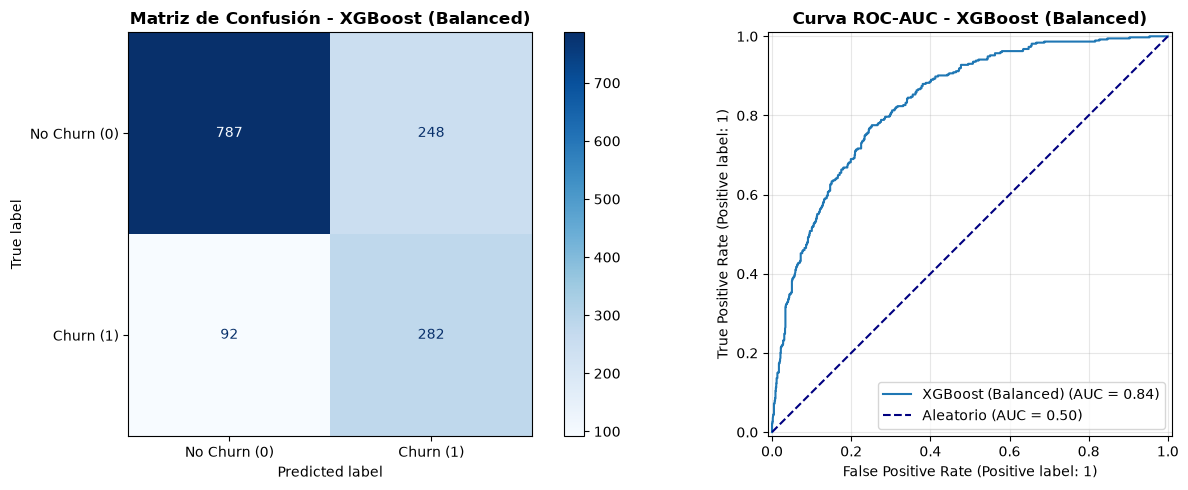

In [37]:
# Ejecución del modelo XGBoost pero incluyendo el parametro 'scale_pos_weight' para tener en cuenta el desbalance 
# que existe en los datos con respecto a la proporción de datos de prueba de noChurn(0) con Churn(1).
# Con esto se consigue aumentar el RECALL, es decir, bajan los FN (Falsos Negativos), PERO al ser mas sensible, reduce la precisión, es decir, se genera mayor numero de FP (Falsos Positivos).

import numpy as np
from xgboost import XGBClassifier

# 1. Calcular automáticamente la proporción sobre y_train
count_negative = (y_train == 0).sum()
count_positive = (y_train == 1).sum()
scale_weight = count_negative / count_positive

print(f"Casos 0 (No Churn): {count_negative}")
print(f"Casos 1 (Churn):    {count_positive}")
print(f"scale_pos_weight calculado: {scale_weight:.2f}\n")

# 2. Inicializar XGBoost con el parámetro balanceado
model_xgb_balanced = XGBClassifier(scale_pos_weight=scale_weight, n_estimators=100, learning_rate=0.1, random_state=42)

# 3. Entrenar el modelo
model_xgb_balanced.fit(X_train, y_train)

y_pred_xgbal = model_xgb_balanced.predict(X_test)
y_pred_proba_xgbal = model_xgb_balanced.predict_proba(X_test)[:, 1]

# Mostrar métricas de evaluación principales
print("--- Informe de Clasificación ---")
print(classification_report(y_test, y_pred_xgbal))

print("--- Matriz de Confusión ---")
print(confusion_matrix(y_test, y_pred_xgbal))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_xgbal):.4f}")

# 4. Mostrar la matriz de confusión 
evaluar_modelo_individual( model_xgb_balanced, X_test, y_test, nombre_modelo="XGBoost (Balanced)")



ROC-AUC Regresión Logística std: 0.8421
ROC-AUC Random Forest:           0.8248
ROC-AUC XGBoost bal:             0.8354



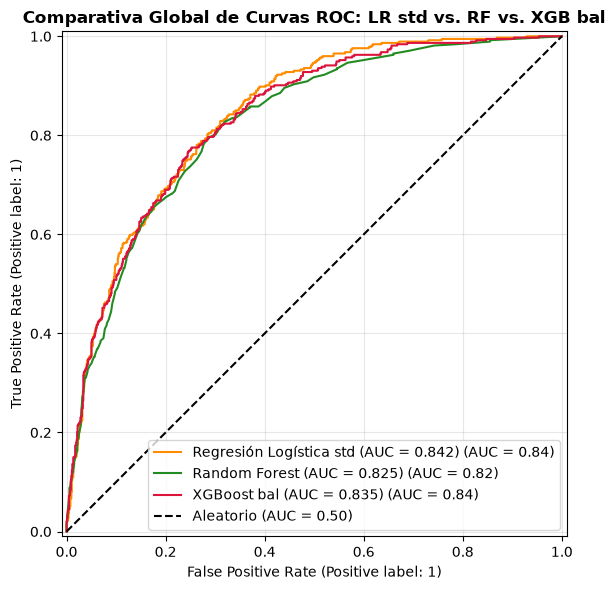

In [38]:
# Se visualizan sobre el mismo gráfico las curvas ROC para las 3 mejores modelos presentados 

import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import RocCurveDisplay, classification_report, roc_auc_score


# Calcular los puntajes ROC-AUC finales
auc_lr = roc_auc_score(y_test, y_pred_proba_std)
auc_rf = roc_auc_score(y_test, y_pred_proba_rf)
auc_xgb = roc_auc_score(y_test, y_pred_proba_xgbal)

print(f"ROC-AUC Regresión Logística std: {auc_lr:.4f}")
print(f"ROC-AUC Random Forest:           {auc_rf:.4f}")
print(f"ROC-AUC XGBoost bal:             {auc_xgb:.4f}\n")

# 4. Superponer las 3 Curvas ROC en una sola figura
# 4. Superponer las 3 Curvas ROC en una sola figura
fig, ax = plt.subplots(figsize=(9, 6))

# Regresión Logística
disp_lr = RocCurveDisplay.from_estimator(
    model_lrstd, 
    X_test_scaled, 
    y_test, 
    ax=ax,
    name=f"Regresión Logística std (AUC = {auc_lr:.3f})"
)
plt.setp(disp_lr.line_, color="darkorange")

# Random Forest
disp_rf = RocCurveDisplay.from_estimator(
    model_rf, 
    X_test, 
    y_test, 
    ax=ax,
    name=f"Random Forest (AUC = {auc_rf:.3f})"
)
plt.setp(disp_rf.line_, color="forestgreen")

# XGBoost
disp_xgb = RocCurveDisplay.from_estimator(
    model_xgb_balanced, 
    X_test, 
    y_test, 
    ax=ax,
    name=f"XGBoost bal (AUC = {auc_xgb:.3f})"
)
plt.setp(disp_xgb.line_, color="crimson")

# Línea de referencia (clasificador aleatorio)
ax.plot([0, 1], [0, 1], color="black", linestyle="--", label="Aleatorio (AUC = 0.50)")

ax.set_title("Comparativa Global de Curvas ROC: LR std vs. RF vs. XGB bal", fontsize=12, fontweight="bold")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

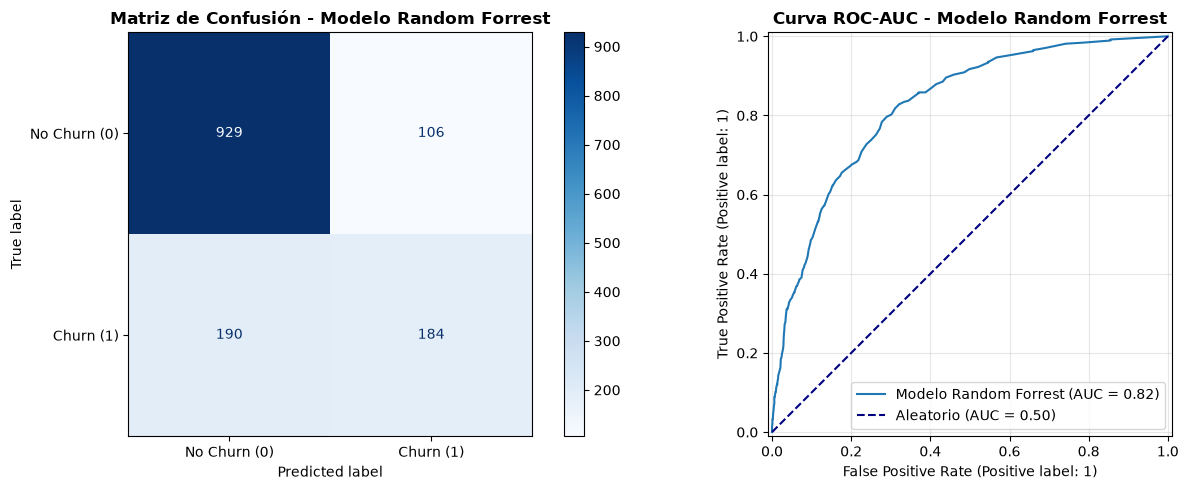

In [39]:
# Muestra la Matriz de Confusión y la curva ROC-AUC para Random Forrest

evaluar_modelo_individual(model_rf, X_test, y_test, nombre_modelo="Modelo Random Forrest")

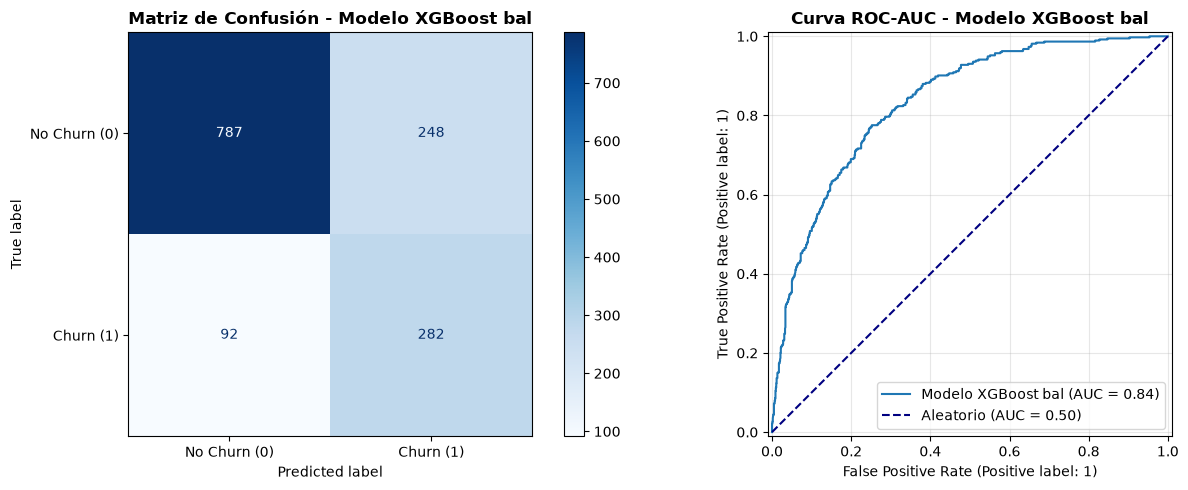

In [40]:
# Muestra la Matriz de Confusión y la curva ROC-AUC para Modelo XGBoost

evaluar_modelo_individual(model_xgb_balanced, X_test, y_test, nombre_modelo="Modelo XGBoost bal")

In [41]:
# Sobre le modelo model_xgb_balanced (XGBClassifier bal), vamos a realizar un cambio en el umbral y lo vamos a reducir a 35% por ejemplo para ver qué ocurre. 
# Básicamente esperaremos que el modelo catalogue más FP por lo que reducirá los FN que es el objetivo de un proyecto de Churn

from sklearn.metrics import classification_report, confusion_matrix

# 1. Obtenemos la probabilidad continua de pertenecer a la clase 1 (Churn)
y_probs =  model_xgb_balanced.predict_proba(X_test)[:, 1]

# 2. Aplicamos un umbral personalizado (ej. 0.35)
umbral = 0.35
y_pred_custom = (y_probs >= umbral).astype(int)

# 3. Imprimimos las nuevas métricas
print(f"--- Matriz de Confusión (Umbral {umbral}) ---")
print(confusion_matrix(y_test, y_pred_custom))

print("\n--- Informe de Clasificación ---")
print(classification_report(y_test, y_pred_custom))

--- Matriz de Confusión (Umbral 0.35) ---
[[687 348]
 [ 65 309]]

--- Informe de Clasificación ---
              precision    recall  f1-score   support

           0       0.91      0.66      0.77      1035
           1       0.47      0.83      0.60       374

    accuracy                           0.71      1409
   macro avg       0.69      0.74      0.68      1409
weighted avg       0.80      0.71      0.72      1409



### Influencia de las características en el cálculo del Churn (continuación). 

- Para Logistic reg ya vimos que tenemos: 
    - tenure
    - InternetService_Fiber optic
    - Contract
    - TotalCharges                
    - MonthlyCharges

- Para RF y Xboost tenemos casi las mismas, vamos a quedarnos con la intersección de las más relevantes para luego poder analizar en detalle:
    - tenure
    - Contract
    - MonthlyCharges 
    - InternetService_Fiber optic

- Para un mejor entendimiento, utilizaremos libreria Shap que permite mostrar en un gráfico la influencia de las características por medio de diferentes ejes.

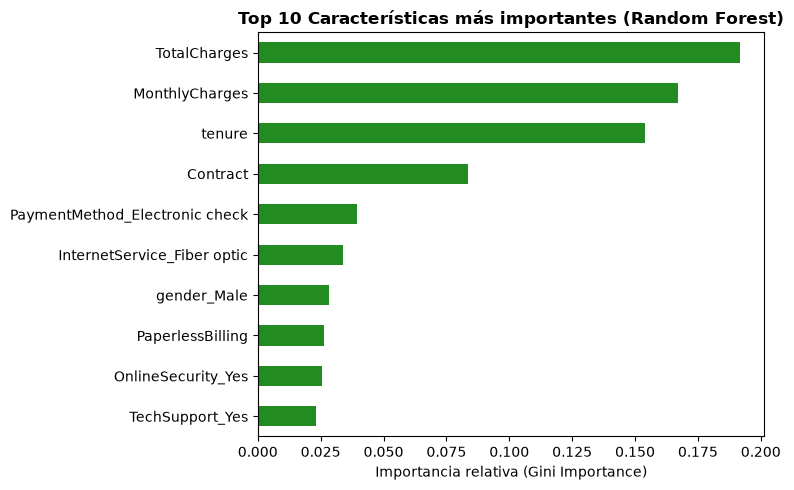

In [42]:
# Con RandomForest se pueden visualizar la importancia de las caracteristicas. A destacar:
# tenure                            0.154133
# Contract                          0.083524
# PaymentMethod_Electronic check    0.039364
# InternetService_Fiber optic       0.033692


feature_imp = (
    pd.Series(model_rf.feature_importances_, index=X_train.columns)
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(8, 5))
feature_imp.plot(kind="barh", color="forestgreen")
plt.gca().invert_yaxis()
plt.title("Top 10 Características más importantes (Random Forest)", fontweight="bold",)
plt.xlabel("Importancia relativa (Gini Importance)")
plt.tight_layout()
plt.show()

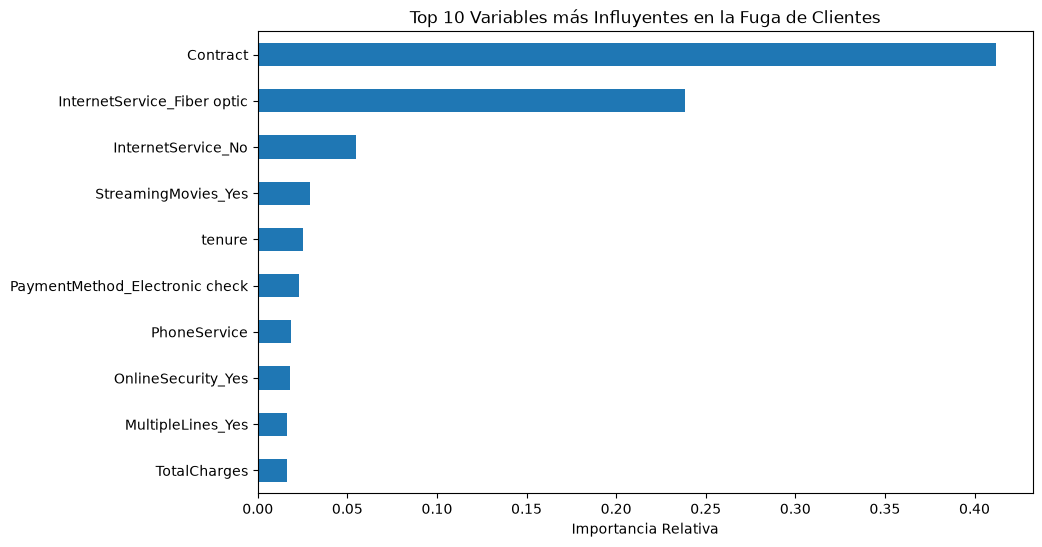

In [43]:
# Con XGBoosting bal se pueden visualizar la importancia de las caracteristicas. A destacar:
# Contract                          0.411931
# InternetService_Fiber optic       0.238492
# InternetService_No                0.054719
# StreamingMovies_Yes               0.029081
# tenure                            0.025050


# Extraer importancia
importancias = pd.Series(model_xgb_balanced.feature_importances_, index=X_train.columns)
importancias_top10 = importancias.nlargest(10)

# Graficar
plt.figure(figsize=(10, 6))
importancias_top10.plot(kind='barh')
plt.title("Top 10 Variables más Influyentes en la Fuga de Clientes")
plt.xlabel("Importancia Relativa")
plt.gca().invert_yaxis()
plt.show()

In [ ]:
# %pip install shap

   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/41.9 MB ? eta -:--:--
    --------------------------------------- 0.5/41.9 MB 1.2 MB/s eta 0:00:35
    --------------------------------------- 0.8/41.9 MB 1.2 MB/s eta 0:00:35
   - -------------------------------------- 1.0/41.9 MB 1.2 MB/s eta 0:00:35
   - -------------------------------------- 1.3/41.9 MB 1.2 MB/s eta 0:00:35
   - -------------------------------------- 1.6/41.9 MB 1.2 MB/s eta 0:00:34
   - -------------------------------------- 1.8/41.9 MB 1.2 MB/s eta 0:00:34
   -- ------------------------------------- 2.1/41.9 MB 1.2 MB/s eta 0:00:34
   -- ------------------------------------- 2.4/41.9 MB 1.2 MB/s eta 0:00:34
   -- ------------------------------------- 2.6/41.9 MB 1.2 MB/s eta 0:00:34
   -- ------------------------------------- 2.9/41.9 MB 1.2 MB/s eta 0:00:33
   --- -------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


c:\Projects\Telco-Churn\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


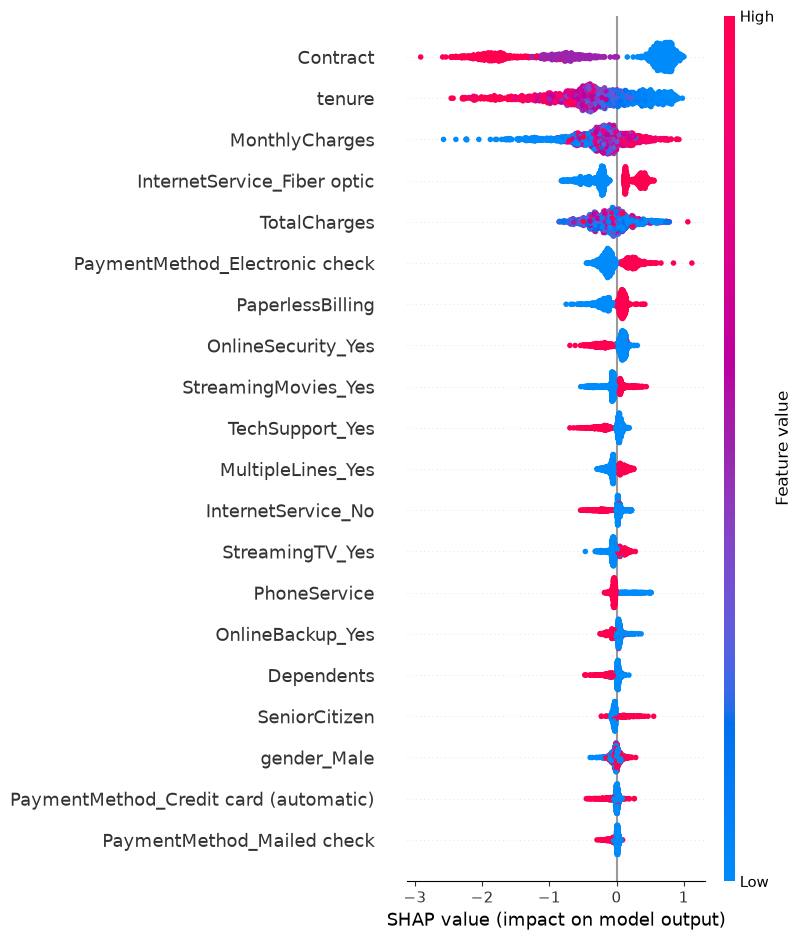

In [44]:
import shap

# Crear el explicador de SHAP para el modelo de XGBoost
explainer = shap.TreeExplainer(model_xgb_balanced)
shap_values = explainer(X_test)

# Graficar el impacto de las características
shap.summary_plot(shap_values, X_test)

### Explicación gráfico Shap sobre la influencia de las características en la variable objetivo 

- El gráfico SHAP muestra varias dimensiones: variable, valor de la variable, impacto y densidad de puntos. 
- Las características más influyentes a la hora de otorgar un valor a la variable objetivo Churn (0 o 1) son las siguientes: **Contract, tenure, MonthlyCharges e InternetService_Fiber optic**.
- Explicación de variable **"Contract"**. Es la variable ordinal que categorizamos con: 1-mensual, 2-anual, 3-bianual. Sabemos que valores SHAP > 0 tienen un alto impacto en categorizar como Churn=1. Vemos que los valores que se encuentran a la derecha del 0 son los valores bajos (mensual), y por el contrario, los que se encuentran a la izquierda del 0 tienen poco impacto y son los valores medios y altos (anual y bianual). El volumen se concentra principalmente en los valores bajos. 

### Resumen del estudio de fuga de clientes

Como resumen al estudio realizado sobre la probabilidad de fuga de clientes de una compañía telecomunicaciones, tenemos:
- Hemos partido de un fichero con los datos de clientes. Una muestra con 7.043 filas y 21 variables.
- Lo hemos revisado identificando variables cualitativas y cuantitativas, hemos detectado errores en los datos, valores nulos, y hemos realizado transformaciones para pasar a numéricas todas las variables. Tambien hemos escalado algunas variables numéricas que partian de escalas muy dispares (importante para Logistic Reg).
- Hemos separado la muestra y hemos tenido en cuenta el desbalanceo en los datos de prueba de la variable objetivo. 
- A partir de aqui hemos entrenado la muestra contra varios modelos diferentes: Logistic Reg, Random Forest, y XGBoosting
- En todas ellos hemos mostrado métricas, matriz de confusión y curva ROC-AUC. En los proyectos de este tipo (churn) se trata de minimizar el valor de FN, Falsos Negativos, esto es, clientes que se han ido y el modelo predijo que se mantendrían.
- En los modelos como XGB hemos realizado algún ajuste para tener en cuenta el desbalanceo en los datos.
- En algunos de ellos, el modelo nos ha permitido mostrar el listado de características más influyentes sobre el valor objetivo, y las principales características las hemos explicado empleando SHAP.

### Índice de Youden (sobre Logistic Reg) para encontrar el umbral óptimo
El Índice de Youden mide la distancia vertical máxima entre la curva ROC y la línea diagonal de clasificación aleatoria. 

En este caso, obtenemos estos valores: 
- Umbral óptimo (Youden): 0.2351
- Recall (TPR) alcanzado: 82.89%
- Falsos Positivos (FPR) tolerados: 31.01%

Aunque el Índice de Youden es un estándar clásico en medicina o diagnóstico, en Ciencia de Datos aplicada a negocio **con datos desbalanceados tiene una limitación importante**:
- Asume peso simétrico: Trata igual un fallo en Sensibilidad que un fallo en Especificidad (asume que 1% de ganancia en Recall vale lo mismo que 1% de pérdida en Especificidad).
- Sesgo de la clase mayoritaria: En problemas desbalanceados (73% No Churn vs. 27% Churn), la Especificidad se calcula sobre un denominador muy grande (los 1.035 clientes que no se van), lo que infla artificialmente la métrica.

**Recomendación**: Este índice nos sirve de acercamiento pero en problemas de Churn o detección de fraude desbalanceados, es preferible buscar el umbral óptimo evaluando la Curva Precision-Recall (PR-AUC) o definiendo una Matriz de Costes Económicos (donde asignas un coste a los Falsos Negativos frente a los Falsos Positivos) en lugar de apoyarnos únicamente en el Índice de Youden. Lo veremos a continuación.

In [45]:
# Para calcular el Índice J de Youden para cada umbral. 

import numpy as np
from sklearn.metrics import roc_curve, classification_report, confusion_matrix

# 1. Extraer FPR, TPR y los umbrales probados por la curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba_std)

# 2. Calcular el Índice J de Youden para cada umbral
youden_j = tpr - fpr

# 3. Identificar el umbral que maximiza J
ix = np.argmax(youden_j)
optimal_threshold = thresholds[ix]

print(f"Umbral por defecto: 0.5000")
print(f"Umbral óptimo (Youden): {optimal_threshold:.4f}")
print(f"Recall (TPR) alcanzado: {tpr[ix]:.2%}")
print(f"Falsos Positivos (FPR) tolerados: {fpr[ix]:.2%}")

# 4. Aplicar el nuevo umbral a las probabilidades de test
y_pred_optimal = (y_pred_proba_std >= optimal_threshold).astype(int)

# 5. Comparar el informe de clasificación
print("\n--- Informe de Clasificación con Umbral Óptimo ---")
print(classification_report(y_test, y_pred_optimal))

print("--- Matriz de Confusión ---")
print(confusion_matrix(y_test, y_pred_optimal))


Umbral por defecto: 0.5000
Umbral óptimo (Youden): 0.2351
Recall (TPR) alcanzado: 82.89%
Falsos Positivos (FPR) tolerados: 31.01%

--- Informe de Clasificación con Umbral Óptimo ---
              precision    recall  f1-score   support

           0       0.92      0.69      0.79      1035
           1       0.49      0.83      0.62       374

    accuracy                           0.73      1409
   macro avg       0.70      0.76      0.70      1409
weighted avg       0.80      0.73      0.74      1409

--- Matriz de Confusión ---
[[714 321]
 [ 64 310]]


### Curva PR-AUC para Logistic Reg std

En la ejecución obtenemos PR-AUC = 0.6336

- Para empezar, el modelo parte de una baseline del 26.5% (y no de 50%) que es la proporción de 1 que hay en el conjunto de test.
- Como conclusión:
    - 2.4 veces superior al azar (se obtiene de dividir 0.6336/0.265): Un clasificador aleatorio tiene un área de 0.265. Lograr un 0.6336 significa que el modelo aporta un volumen masivo de información 
 predictiva sobre el azar. Para un dataset desbalanceado (~27% churn), un área PR de 0.63+ se considera un modelo robusto y listo para producción.
    - Zonas de operación en la curva:
        - Zona Alta Precision (Izquierda, Recall ~30% - Precision ~80%): Es una estrategia "francotirador". Pocas falsas alarmas (FP bajo), pero dejas escapar al 70% de los clientes que se van.
        - Zona Equilibrada (Centro, Recall ~75% - Precision ~50%): Duplicas la probabilidad de acertar frente al azar (50% vs 26.5%) capturando a 3 de cada 4 clientes en riesgo. 
        - Zona Alta Cobertura (Derecha, Recall ~95% - Precision ~30%): Capturas casi todo el churn, pero disparas los costes operativos por exceso de falsas alarmas. 


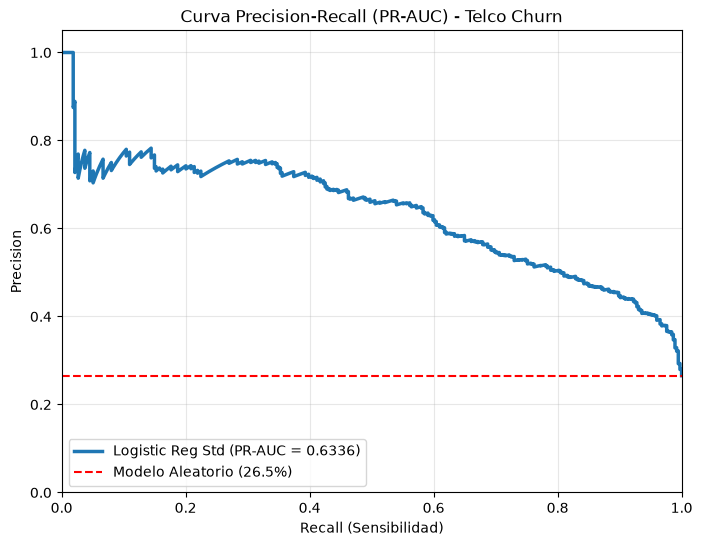

In [46]:
# Grafica de curva PR-AUC (Precision Recall)
# Vamos a calcularla para el mejor modelo que hemos obtenido: Logistic reg std
 
from sklearn.metrics import precision_recall_curve, auc

# 2. Calcular Precision, Recall y umbrales
precision, recall, thresholds = precision_recall_curve(y_test, y_pred_proba_std)
pr_auc = auc(recall, precision)

# 3. Graficar la curva PR
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Logistic Reg Std (PR-AUC = {pr_auc:.4f})', color='#1f77b4', lw=2.5)

# Línea base aleatoria = prevalencia del churn (~26.5%)
prevalencia = y_test.mean()
plt.axhline(y=prevalencia, color='red', linestyle='--', label=f'Modelo Aleatorio ({prevalencia:.1%})')

plt.title('Curva Precision-Recall (PR-AUC) - Telco Churn', fontsize=12)
plt.xlabel('Recall (Sensibilidad)')
plt.ylabel('Precision')
plt.ylim(0.0, 1.05)
plt.xlim(0.0, 1.0)
plt.grid(True, alpha=0.3)
plt.legend(loc="lower left")
plt.show()

### Función de coste

- Planteamos una función que calcule el coste de la campaña de mantenimiento de clientes. 
    - coste_fn=500. Penalizamos en 500€ a los FN (clientes que se fugan y el modelo no detecta).
    - coste_fp=15. Estimamos un coste de 15€ para FP (clientes que no tenían pensado irse, falsa alarma).
    - coste_tp=15. Estimamos un coste de 15€ para TP (clientes que sí tenían pensado irse, campaña efectiva).
    - coste_tn=0. No incurrimos en coste a los TN (clientes que se mantienen).
- Resultados DICTAMEN DE OPTIMIZACIÓN FINANCIERA ---
    - Umbral Óptimo de Decisión: 0.04
    - Coste Mínimo del Test: 18,095.00 €
    - Recall Conseguido: 98.93%
    - Falsos Negativos (Clientes Perdidos): 4
    - Falsos Positivos (Campañas Desperdiciadas): 703


In [47]:
# Función de Optimización por Matriz de Coste 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def optimizar_umbral_financiero(y_true, y_probs, coste_fn=500, coste_fp=15, coste_tp=15, coste_tn=0):
    """
    Calcula el umbral de decisión que minimiza el coste financiero total en euros.
    
    Parámetros:
    -----------
    y_true : array-like
        Etiquetas reales del conjunto de test (0 o 1).
    y_probs : array-like
        Probabilidades predichas de la clase 1 (Churn) obtenidas con predict_proba()[:, 1].
    coste_fn : float
        Coste de perder a un cliente no detectado (LTV perdido).
    coste_fp : float
        Coste de enviar una campaña a un cliente que se iba a quedar.
    coste_tp : float
        Coste de la campaña aplicada a un cliente que sí se iba a ir.
    coste_tn : float
        Coste de no actuar sobre un cliente que se queda.
        
    Retorna:
    --------
    optimo : dict
        Diccionario con el umbral que minimiza el coste, el coste total y el desglose de métricas.
    df_resultados : DataFrame
        Tabla detallada con la evaluación de todos los umbrales.
    """
    umbrales = np.linspace(0.01, 0.99, 100)
    resultados = []

    for umbral in umbrales:
        y_pred = (y_probs >= umbral).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

        # Cálculo del coste financiero global
        coste_total = (fn * coste_fn) + (fp * coste_fp) + (tp * coste_tp) + (tn * coste_tn)

        resultados.append({
            'umbral': umbral,
            'coste_total_eur': coste_total,
            'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp,
            'recall': tp / (tp + fn) if (tp + fn) > 0 else 0,
            'precision': tp / (tp + fp) if (tp + fp) > 0 else 0
        })

    df_resultados = pd.DataFrame(resultados)

    # Identificar el punto de coste mínimo
    idx_optimo = int(df_resultados['coste_total_eur'].to_numpy().argmin())
    optimo = df_resultados.iloc[idx_optimo].to_dict()

    # Visualización de la curva de coste frente al umbral
    plt.figure(figsize=(10, 5))
    plt.plot(df_resultados['umbral'], df_resultados['coste_total_eur'], label='Coste Total Estimado (€)', color='#1f77b4', lw=2.5)
    plt.axvline(x=optimo['umbral'], color='red', linestyle='--', label=f"Umbral Óptimo ({optimo['umbral']:.2f})")
    plt.scatter(optimo['umbral'], optimo['coste_total_eur'], color='red', s=80, zorder=5)
    
    plt.title(f"Optimización Financiera: Umbral Óptimo = {optimo['umbral']:.2f} (Coste Mínimo: {optimo['coste_total_eur']:,.0f} €)", fontsize=12)
    plt.xlabel("Umbral de Decisión")
    plt.ylabel("Coste Financiero Total (€)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    return optimo, df_resultados

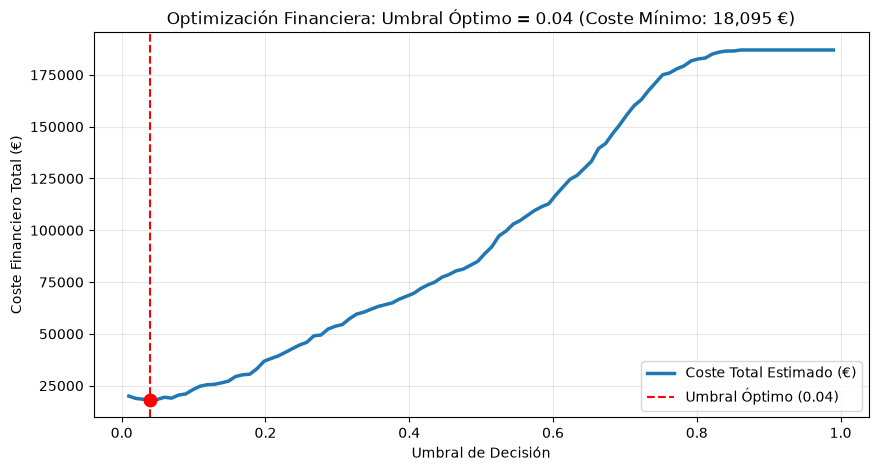

--- DICTAMEN DE OPTIMIZACIÓN FINANCIERA ---
Umbral Óptimo de Decisión: 0.04
Coste Mínimo del Test: 18,095.00 €
Recall Conseguido: 98.93%
Falsos Negativos (Clientes Perdidos): 4
Falsos Positivos (Campañas Desperdiciadas): 703


In [48]:
''' 1. Tenemos las probabilidades predichas de los diferentes modelos ejecutados: lr, lr_std, rf, xgb, xgb_bal
y_pred_proba_lr    --> 2º
y_pred_proba_std   --> 1º
y_pred_proba_rf    --> 5º
y_pred_proba_xgb   --> 4º
y_pred_proba_xgbal --> 3º
''' 

# 2. Ejecutamos la función con los costes hipotéticos
resultado_optimo, df_curva = optimizar_umbral_financiero(
    y_true=y_test, 
    y_probs=y_pred_proba_std, 
    coste_fn=500,  # 500 € por cliente perdido
    coste_fp=15,   # 15 € por falsa alarma
    coste_tp=15,   # 15 € por campaña efectiva
    coste_tn=0
)

# 3. Imprimimos el dictamen para el Informe Ejecutivo
print(f"--- DICTAMEN DE OPTIMIZACIÓN FINANCIERA ---")
print(f"Umbral Óptimo de Decisión: {resultado_optimo['umbral']:.2f}")
print(f"Coste Mínimo del Test: {resultado_optimo['coste_total_eur']:,.2f} €")
print(f"Recall Conseguido: {resultado_optimo['recall']:.2%}")
print(f"Falsos Negativos (Clientes Perdidos): {int(resultado_optimo['fn'])}")
print(f"Falsos Positivos (Campañas Desperdiciadas): {int(resultado_optimo['fp'])}")

### Alternativas a campañas con presupuesto "ilimitado"

 - En la realidad, los departamentos dentro de las empresas manejan presupuestos limitados, por lo que tendriamos que ejecutar una función parecida a la anterior pero teniendo en cuenta que no se supere el presupuesto establecido.
    - Resultados DICTAMEN DE OPTIMIZACIÓN FINANCIERA CON PRESUPUESTO LIMITADO ---
    - Umbral Óptimo de Decisión: 0.16
    - Coste coste_neto_total del Test: 29,430.00 €
    - Coste gasto_campana del Test: 11,430.00 €
    - Recall Conseguido: 90.37%
    - Falsos Negativos (Clientes Perdidos): 36
    - Falsos Positivos (Campañas Desperdiciadas): 424

- Otra posibilidad es que exista una limitación operativa, por lo que tambien se podría ejecutar una función para obtener los top N clientes con mayor prob de fuga para poder aplicar campañas sobre ellos.
    - Resultados ESTRATEGIA TOP-200 CLIENTES ---
    - Umbral implícito resultante: 0.6042
    - Recall conseguido: 38.77%
    - Fugas capturadas: 145 de 374 clientes totales en churn

In [49]:
# Función de coste teniendo en cuenta un presupuesto definido

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def optimizar_umbral_con_presupuesto(
    y_true, 
    y_probs, 
    coste_fn=500, 
    coste_campana=15, 
    presupuesto_max_campana=10000
):
    """
    Minimiza el coste neto sujetándose a un presupuesto máximo en euros para campañas de retención.
    """
    umbrales = np.linspace(0.01, 0.99, 100)
    resultados = []

    for umbral in umbrales:
        y_pred = (y_probs >= umbral).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

        # 1. Gasto directo en ejecutar la campaña (TP + FP)
        gasto_campana = (tp + fp) * coste_campana
        
        # 2. Pérdida financiera total por fugas no detectadas + gasto en campañas
        coste_neto_total = (fn * coste_fn) + gasto_campana

        resultados.append({
            'umbral': umbral,
            'coste_neto_total': coste_neto_total,
            'gasto_campana': gasto_campana,
            'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp,
            'recall': tp / (tp + fn) if (tp + fn) > 0 else 0,
            'precision': tp / (tp + fp) if (tp + fp) > 0 else 0,
            'clientes_impactados': tp + fp
        })

    df_resultados = pd.DataFrame(resultados)

    # Filtrar solo los umbrales que NO superan el presupuesto de la empresa
    df_validos = df_resultados[df_resultados['gasto_campana'] <= presupuesto_max_campana]

    if df_validos.empty:
        raise ValueError(f"El presupuesto de {presupuesto_max_campana} € es demasiado bajo para este dataset.")

    # Seleccionar el mejor umbral dentro de los válidos
    idx_optimo = int(df_validos['coste_neto_total'].to_numpy().argmin())
    optimo = df_validos.iloc[idx_optimo].to_dict()

    # Visualización
    plt.figure(figsize=(10, 5))
    plt.plot(df_resultados['umbral'], df_resultados['coste_neto_total'], label='Coste Neto Sin Restricción (€)', color='gray', linestyle='--')
    plt.plot(df_validos['umbral'], df_validos['coste_neto_total'], label='Zona Viable Financieramente', color='#1f77b4', lw=2.5)
    
    plt.axvline(x=optimo['umbral'], color='red', linestyle='--', label=f"Umbral Viable Óptimo ({optimo['umbral']:.2f})")
    plt.scatter(optimo['umbral'], optimo['coste_neto_total'], color='red', s=80, zorder=5)

    plt.title(f"Optimización con Límite de Presupuesto ({presupuesto_max_campana:,.0f} € max)\n"
              f"Umbral: {optimo['umbral']:.2f} | Recall: {optimo['recall']:.1%} | Gasto Campaña: {optimo['gasto_campana']:,.0f} €", fontsize=11)
    plt.xlabel("Umbral de Decisión")
    plt.ylabel("Coste Total para la Empresa (€)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    return optimo, df_resultados

In [50]:
# Función por limitación comercial, identificar los Top n clientes

def seleccionar_top_n_clientes(y_true, y_probs, capacidad_max_llamadas=200):
    """
    Selecciona exactamente a los N clientes con mayor riesgo de churn.
    """
    df_eval = pd.DataFrame({
        'y_true': y_true,
        'prob_churn': y_probs
    }).sort_values(by='prob_churn', ascending=False)

    # Cortar en los N clientes de mayor riesgo
    df_eval['pred_churn'] = 0
    top_indices = df_eval.index[:capacidad_max_llamadas]
    df_eval.loc[top_indices, 'pred_churn'] = 1

    # Umbral implícito resultante
    umbral_implicito = df_eval.iloc[capacidad_max_llamadas - 1]['prob_churn']
    
    # Métricas para calcular el RECALL 
    tp = ((df_eval['pred_churn'] == 1) & (df_eval['y_true'] == 1)).sum() # De las 200 personas que marcamos como fugas (pred_churn = 1) y que efectivamnete eran fugas (y_true = 1)
    fn = ((df_eval['pred_churn'] == 0) & (df_eval['y_true'] == 1)).sum() # Del total de personas que no se preveía que fueran fugas (pred_churn = 0), y que eran fugas (y_true = 1)
    recall = tp / (tp + fn)

    print(f"--- ESTRATEGIA TOP-{capacidad_max_llamadas} CLIENTES ---")
    print(f"Umbral implícito resultante: {umbral_implicito:.4f}")
    print(f"Recall conseguido: {recall:.2%}")
    print(f"Fugas capturadas: {tp} de {tp + fn} clientes totales en churn")
    
    return umbral_implicito, recall

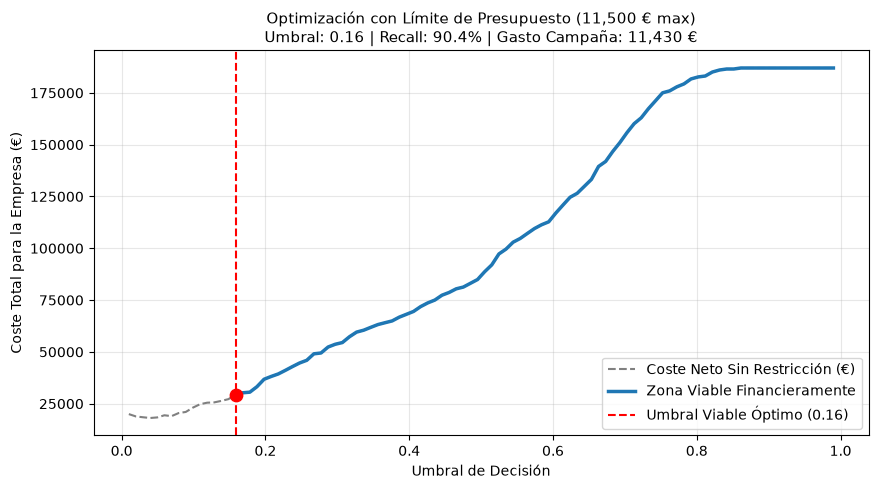

--- DICTAMEN DE OPTIMIZACIÓN FINANCIERA CON PRESUPUESTO LIMITADO ---
Umbral Óptimo de Decisión: 0.16
Coste coste_neto_total del Test: 29,430.00 €
Coste gasto_campana del Test: 11,430.00 €
Recall Conseguido: 90.37%
Falsos Negativos (Clientes Perdidos): 36
Falsos Positivos (Campañas Desperdiciadas): 424


In [51]:
# Ejecutamos la función con los costes hipotéticos que incluyen PRESUPUESTO

resultado_optimo, df_curva = optimizar_umbral_con_presupuesto(
    y_true=y_test, 
    y_probs=y_pred_proba_std, 
    coste_fn=500, 
    coste_campana=15, 
    presupuesto_max_campana=11500
)

# 3. Imprimimos el dictamen para el Informe Ejecutivo
print(f"--- DICTAMEN DE OPTIMIZACIÓN FINANCIERA CON PRESUPUESTO LIMITADO ---")
print(f"Umbral Óptimo de Decisión: {resultado_optimo['umbral']:.2f}")
print(f"Coste coste_neto_total del Test: {resultado_optimo['coste_neto_total']:,.2f} €")
print(f"Coste gasto_campana del Test: {resultado_optimo['gasto_campana']:,.2f} €")
print(f"Recall Conseguido: {resultado_optimo['recall']:.2%}")
print(f"Falsos Negativos (Clientes Perdidos): {int(resultado_optimo['fn'])}")
print(f"Falsos Positivos (Campañas Desperdiciadas): {int(resultado_optimo['fp'])}")

In [ ]:
# Top N clientes con alta prob de Churn 

umbral_implicito, recall = seleccionar_top_n_clientes(...)



--- ESTRATEGIA TOP-200 CLIENTES ---
Umbral implícito resultante: 0.6042
Recall conseguido: 38.77%
Fugas capturadas: 145 de 374 clientes totales en churn
